In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/processed/tensift_cleaned.csv", parse_dates=["date"])

lalla = df.loc[df["dam"] == "Lalla Takerkoust"].sort_values("date")

print("Total observations:", lalla.shape[0])
print("Average fill rate:", lalla["fill_rate"].mean())
print("Minimum fill rate:", lalla["fill_rate"].min())
print("Maximum fill rate:", lalla["fill_rate"].max())


In [4]:
average = df.groupby("dam")["reserve_mm3"].mean()

print(average)

dam
Abou El Abess Sebti                  18.927315
Bge My abdrhmane                     48.800043
Lalla Takerkoust                     34.853272
Sd Mohamed Ben Slimane El Jazouli     8.785174
Yacoub El Mansour                    47.234489
Name: reserve_mm3, dtype: float64


In [18]:
df["month"] = df["date"].dt.month
monthly_stats = df.groupby(
    ["dam", "month"]
)["fill_rate"].mean()

print(monthly_stats)

dam                                month
Abou El Abess Sebti                8        89.283314
                                   9        82.645805
                                   10       81.837742
Bge My abdrhmane                   8        84.531003
                                   9        82.978358
                                   10       80.677419
Lalla Takerkoust                   8        76.428571
                                   9        64.663322
                                   10       64.528065
Sd Mohamed Ben Slimane El Jazouli  8        75.358874
                                   9        71.051990
                                   10       67.677742
Yacoub El Mansour                  8        85.844465
                                   9        85.216768
                                   10       75.690645
Name: fill_rate, dtype: float64


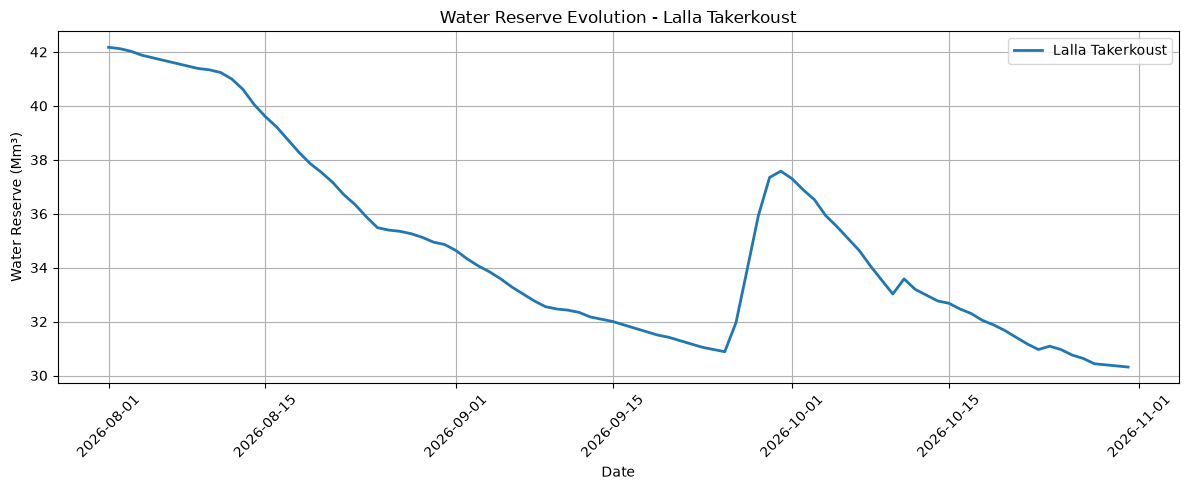

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    lalla["date"],
    lalla["reserve_mm3"],
    label="Lalla Takerkoust",
    linewidth=2
)

plt.title("Water Reserve Evolution - Lalla Takerkoust")

plt.xlabel("Date")
plt.ylabel("Water Reserve (Mm³)")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
## for other dams
Yacoub_El_Mansour = df.loc[df["dam"] == "Yacoub El Mansour"].sort_values("date")
print(Yacoub_El_Mansour["fill_rate"].mean())
plt.figure(figsize=(12, 5))
plt.plot( Yacoub_El_Mansour["date"] , 
          Yacoub_El_Mansour["fill_rate"] ,
          label = "Yacoub El Mansour",
          linewidth = 2 
        )
plt.title("Fill Rate Evolution - Yacoub El Mansour")

plt.xlabel("Date")
plt.ylabel("Fill Rate (%)")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


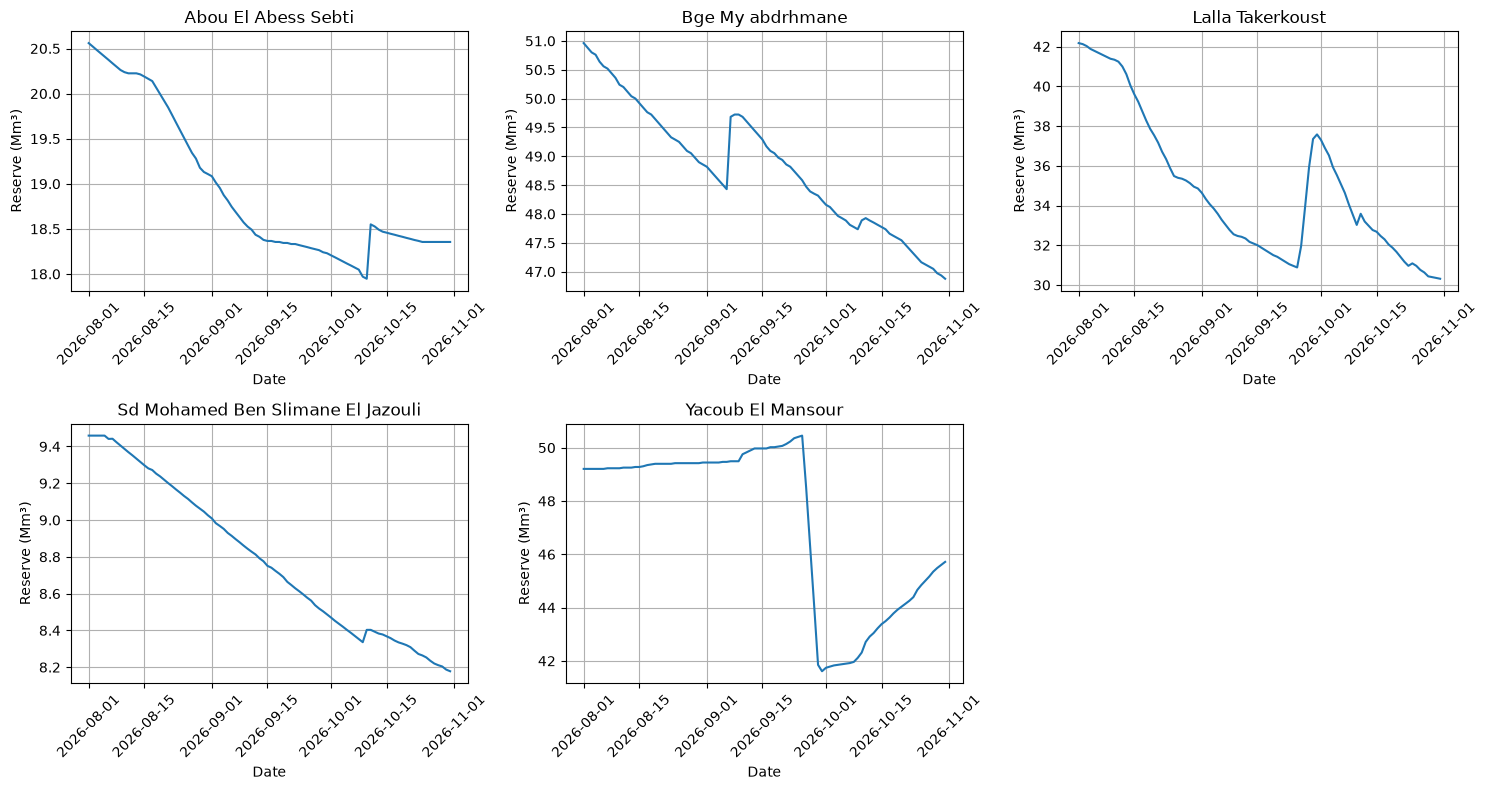

In [39]:


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes = axes.flatten()

for i, (dam_name, dam_data) in enumerate(df.groupby("dam")):

    dam_data = dam_data.sort_values("date")

    axes[i].plot(
        dam_data["date"],
        dam_data["reserve_mm3"]
    )

    axes[i].set_title(dam_name)
    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Reserve (Mm³)")
    axes[i].grid(True)
    axes[i].tick_params(axis="x", rotation=45)

axes[5].set_visible(False)

plt.tight_layout()
plt.show()

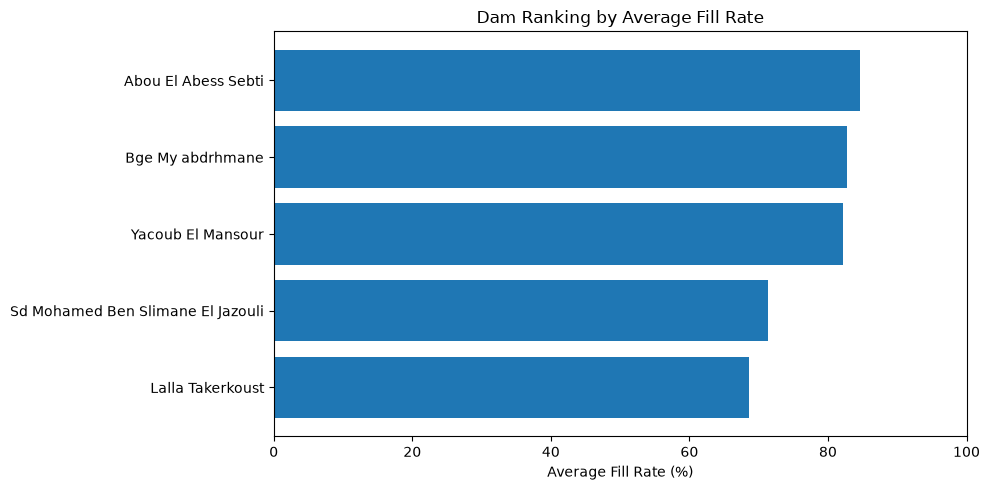

In [41]:
ranking = (
    df.groupby("dam")["fill_rate"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 5))

plt.barh(ranking.index, ranking.values)

plt.xlabel("Average Fill Rate (%)")
plt.title("Dam Ranking by Average Fill Rate")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()